# Homework 3

In [ ]:
!pip install -q bitsandbytes accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 15.4 MB/s eta 0:00:00


In [ ]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage import data

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


---
## 1. Image Classification Using CLIP

We use 5 images from different categories:

| Image | Category | Actual content |
|---|---|---|
| cat | animal | close-up of a cat's face |
| coffee | food / drink | cup of coffee on a red saucer with a spoon |
| motorcycle | vehicle | red motorcycle in a garage |
| rocket | technology | rocket on a launch pad at night |
| astronaut | person | astronaut in an orange suit holding a helmet |

### 1.1 Load the pretrained CLIP model

In [ ]:
from transformers import CLIPModel, CLIPProcessor

clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

### 1.2 Display the images

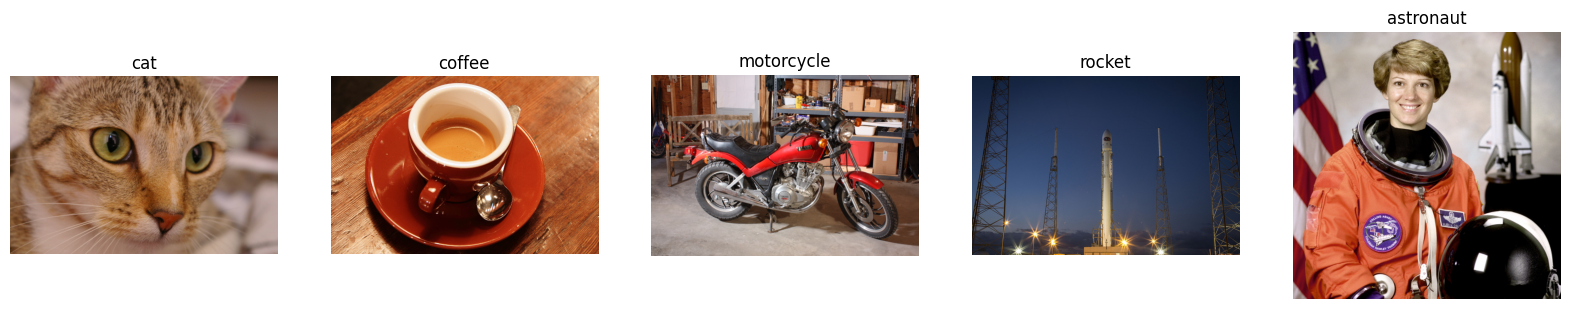

In [ ]:
images = {
    "cat":        Image.fromarray(data.chelsea()),
    "coffee":     Image.fromarray(data.coffee()),
    "motorcycle": Image.fromarray(data.stereo_motorcycle()[0]),
    "rocket":     Image.fromarray(data.rocket()),
    "astronaut":  Image.fromarray(data.astronaut()),
}

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, (name, img) in zip(axes, images.items()):
    ax.imshow(img)
    ax.set_title(name)
    ax.axis("off")
plt.show()

### 1.3 Candidate labels
Each image has 5 candidate labels. The first label is the correct one.

In [ ]:
labels = {
    "cat":        ["cat", "dog", "tiger", "fox", "rabbit"],
    "coffee":     ["cup of coffee", "cup of tea", "bowl of soup", "glass of beer", "plate of pasta"],
    "motorcycle": ["motorcycle", "bicycle", "car", "scooter", "truck"],
    "rocket":     ["rocket", "airplane", "lighthouse", "skyscraper", "radio tower"],
    "astronaut":  ["astronaut", "pilot", "firefighter", "doctor", "soldier"],
}

### 1.4 – 1.6 Similarity scores and predictions
`logits_per_image` is the image–text similarity (cosine similarity × 100). Softmax turns the scores into probabilities.

In [ ]:
def clip_scores(image, texts):
    inputs = clip_processor(text=texts, images=image, return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        outputs = clip_model(**inputs)
    scores = outputs.logits_per_image[0]
    probs = scores.softmax(dim=0)
    return scores.cpu().numpy(), probs.cpu().numpy()

results = []
for name, img in images.items():
    scores, probs = clip_scores(img, labels[name])
    table = pd.DataFrame({"label": labels[name], "similarity": scores.round(2), "probability": probs.round(3)})
    print(f"\nImage: {name}")
    print(table.to_string(index=False))

    predicted = labels[name][probs.argmax()]
    actual = labels[name][0]
    print("Predicted:", predicted, "| Actual:", actual, "| Correct:", predicted == actual)
    results.append({"image": name, "actual": actual, "predicted": predicted, "correct": predicted == actual})

pd.DataFrame(results)


Image: cat
 label  similarity  probability
   cat   26.520000        0.928
   dog   21.459999        0.006
 tiger   23.600000        0.050
   fox   20.690001        0.003
rabbit   22.250000        0.013
Predicted: cat | Actual: cat | Correct: True

Image: coffee
         label  similarity  probability
 cup of coffee   28.020000        0.929
    cup of tea   25.420000        0.069
  bowl of soup   21.620001        0.002
 glass of beer   17.809999        0.000
plate of pasta   17.930000        0.000
Predicted: cup of coffee | Actual: cup of coffee | Correct: True

Image: motorcycle
     label  similarity  probability
motorcycle   27.760000        0.862
   bicycle   22.680000        0.005
       car   20.150000        0.000
   scooter   25.879999        0.131
     truck   21.209999        0.001
Predicted: motorcycle | Actual: motorcycle | Correct: True

Image: rocket
      label  similarity  probability
     rocket   25.959999        0.935
   airplane   16.070000        0.000
 lighthouse

,image,actual,predicted,correct
0,cat,cat,cat,True
1,coffee,cup of coffee,cup of coffee,True
2,motorcycle,motorcycle,motorcycle,True
3,rocket,rocket,rocket,True
4,astronaut,astronaut,astronaut,True


### Answers — Task 1

**1. Did CLIP correctly identify all the images?**
Yes. CLIP predicted the correct label for all 5 images, with high probabilities: cat 0.928, coffee 0.929, motorcycle 0.862, rocket 0.935, astronaut 0.971. These are clear, typical photos, similar to the images CLIP was trained on. The second-best labels were always the most similar ones: *tiger* for the cat (0.050), *cup of tea* for the coffee (0.069), *scooter* for the motorcycle (0.131), *radio tower* for the rocket (0.061) and *pilot* for the astronaut (0.027). So CLIP's "doubts" were reasonable, but the correct label was always clearly the best.

**2. What happens when the correct label is not included among the candidate labels?**
CLIP cannot answer "none of these". It always chooses the most similar label from the given list, so it would predict a wrong label — the one closest in meaning or appearance. From our results, without the correct label CLIP would choose *tiger* for the cat, *cup of tea* for the coffee, *scooter* for the motorcycle, *radio tower* for the rocket and *pilot* for the astronaut, because these had the second-highest scores. Because softmax makes the probabilities sum to 1, this wrong label would then get a high probability, so the model would look confident even though it is wrong.

**3. Why does CLIP compare image and text embeddings instead of using a traditional classification layer?**
CLIP was trained on millions of image–caption pairs to put matching images and texts close to each other in a shared embedding space. A traditional classification layer has a fixed set of classes chosen during training. By comparing image and text embeddings, CLIP can use *any* labels written in natural language at test time, without retraining. This is called zero-shot classification: we only change the list of text labels, as we did for each image above.

---
## 2. Prompt Engineering with CLIP

For every image and every candidate category we use 3 prompts:
1. **Bare label** — `cat`
2. **Template** — `a photo of a cat`
3. **Domain-specific** — a description that fits the image, e.g. `a close-up photo of a cat's face`

In [ ]:
domain_prompts = {
    "cat":        "a close-up photo of a {}'s face",
    "coffee":     "a photo of a {} on a wooden table",
    "motorcycle": "a photo of a {} parked in a garage",
    "rocket":     "a photo of a {} on a launch pad at night",
    "astronaut":  "a portrait photo of a {} holding a helmet",
}

def make_prompts(name, label):
    return {
        "bare":     label,
        "template": f"a photo of a {label}",
        "domain":   domain_prompts[name].format(label),
    }

rows = []
for name, img in images.items():
    for prompt_type in ["bare", "template", "domain"]:
        texts = [make_prompts(name, l)[prompt_type] for l in labels[name]]
        scores, probs = clip_scores(img, texts)
        best = probs.argmax()
        rows.append({
            "image": name,
            "prompt type": prompt_type,
            "prompt (correct label)": texts[0],
            "score (correct label)": round(float(scores[0]), 2),
            "prob (correct label)": round(float(probs[0]), 3),
            "predicted": labels[name][best],
            "correct": best == 0,
        })

prompt_results = pd.DataFrame(rows)
prompt_results

,image,prompt type,prompt (correct label),score (correct label),prob (correct label),predicted,correct
0,cat,bare,cat,26.52,0.928,cat,True
1,cat,template,a photo of a cat,28.28,0.974,cat,True
2,cat,domain,a close-up photo of a cat's face,30.44,0.988,cat,True
3,coffee,bare,cup of coffee,28.02,0.929,cup of coffee,True
4,coffee,template,a photo of a cup of coffee,30.21,0.933,cup of coffee,True
5,coffee,domain,a photo of a cup of coffee on a wooden table,31.32,0.901,cup of coffee,True
6,motorcycle,bare,motorcycle,27.76,0.862,motorcycle,True
7,motorcycle,template,a photo of a motorcycle,28.15,0.793,motorcycle,True
8,motorcycle,domain,a photo of a motorcycle parked in a garage,30.45,0.887,motorcycle,True
9,rocket,bare,rocket,25.96,0.935,rocket,True


Compact comparison tables:

In [ ]:
print("Similarity score of the correct label:")
display(prompt_results.pivot(index="image", columns="prompt type", values="score (correct label)"))

print("Predicted category:")
display(prompt_results.pivot(index="image", columns="prompt type", values="predicted"))

print("Average over all images:")
display(prompt_results.groupby("prompt type")[["score (correct label)", "prob (correct label)", "correct"]].mean())

Similarity score of the correct label:


prompt type,bare,domain,template
image,,,
astronaut,24.23,29.21,27.01
cat,26.52,30.44,28.28
coffee,28.02,31.32,30.21
motorcycle,27.76,30.45,28.15
rocket,25.96,29.21,28.44


Predicted category:


prompt type,bare,domain,template
image,,,
astronaut,astronaut,astronaut,astronaut
cat,cat,cat,cat
coffee,cup of coffee,cup of coffee,cup of coffee
motorcycle,motorcycle,motorcycle,motorcycle
rocket,rocket,rocket,rocket


Average over all images:


,score (correct label),prob (correct label),correct
prompt type,,,
bare,26.498,0.9250,1.0
domain,30.126,0.8334,1.0
template,28.418,0.9348,1.0


### Answers — Task 2

**1. Did changing the prompt affect the similarity scores?**
Yes. Even though the category stays the same, every change in wording changes the text embedding, so the similarity scores changed for every image. For all 5 images the order was the same: bare label < template < domain-specific. On average the score of the correct label was 26.50 for the bare label, 28.42 for the template and 30.13 for the domain-specific prompt (for example, cat: 26.52 → 28.28 → 30.44).

**2. Did prompt engineering change the predicted category for any image?**
No. In the "Predicted category" table the top label is the same for all three prompt types, and the accuracy was 100% for every prompt type. For these clear images the correct label wins with a large margin, so the prompts changed the scores and the probabilities, but not the final prediction. Prompt engineering would matter more for unclear images where two labels have similar scores.

**3. Which prompt worked best for your images, and what might explain the difference?**
The answer depends on what we measure:
- The **domain-specific** prompts gave the **highest similarity scores** for every image (average 30.13). They describe details that are really in the image (garage, launch pad, wooden table), so the text matches the image better.
- The **template** "a photo of a ..." gave the **highest average probability** for the correct label (0.935, compared with 0.925 for the bare label and 0.833 for the domain-specific prompts), so it separated the correct label from the wrong ones best. CLIP was trained on full captions from the internet, not on single words, so a sentence like "a photo of a cat" is closer to what it has seen during training than the bare word "cat".

Because all prompt types had the same accuracy, overall the **template** worked best: it was the most confident and it does not need a special prompt for each image.

**4. Does a higher similarity score always mean that a prompt is objectively better? Explain.**
No, and our results show this clearly. For the **rocket**, the domain-specific prompt gave a higher score for the correct label (29.21) than the template (28.44), but its probability dropped from 0.987 to only **0.417**. The reason is that "...on a launch pad at night" also matches the wrong labels very well (a radio tower or a lighthouse at night also fits the image), so their scores increased even more and the gap became smaller. The same happened for the coffee (domain: highest score 31.32, but probability 0.901 vs 0.933 for the template).
So a context can increase the score of *all* labels. What matters for classification is whether the correct label is ranked first and how big the gap is to the other labels, not the absolute score. Also, we wrote the domain-specific prompts after looking at each image; in a real task we cannot write a special prompt for every image, so a prompt is only objectively better if it improves accuracy on new images.

---
## 3. Image Understanding Using a Generative VLM (LLaVA)

I use **LLaVA-1.5-7B**, loaded in 4-bit so it fits on the free Colab GPU, and 3 images with several objects: `astronaut`, `motorcycle`, `coffee`.

In [ ]:
from transformers import AutoProcessor, LlavaForConditionalGeneration, BitsAndBytesConfig

model_id = "llava-hf/llava-1.5-7b-hf"
vlm = LlavaForConditionalGeneration.from_pretrained(
    model_id,
    quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16),
    device_map="auto",
)
vlm_processor = AutoProcessor.from_pretrained(model_id)

def ask(image, question):
    prompt = f"USER: <image>\n{question} ASSISTANT:"
    inputs = vlm_processor(images=image, text=prompt, return_tensors="pt").to(vlm.device, torch.float16)
    with torch.no_grad():
        output = vlm.generate(**inputs, max_new_tokens=200, do_sample=False)
    text = vlm_processor.decode(output[0], skip_special_tokens=True)
    return text.split("ASSISTANT:")[-1].strip()

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/70.1k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

...

tokenizer.json:   0%|          | 0.00/3.62M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/41.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/552 [00:00<?, ?B/s]

For each image we ask for a description and 3 questions. The **actual answer** column is what is really in the image, so we can compare.

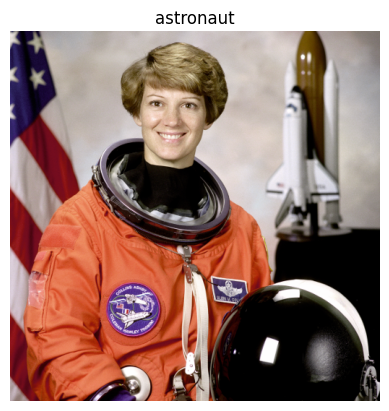

Q: Describe this image.
LLaVA: The image features a woman wearing an orange space suit, standing in front of a flag. She appears to be a space explorer, possibly a female astronaut. The woman is smiling, showcasing her enthusiasm for the space program.

In the background, there are two airplanes visible, one on the left side and the other on the right side of the image. The presence of these airplanes suggests that the location might be near an airport or an airbase.
Actual: A smiling woman astronaut in an orange suit holding a helmet, a US flag on the left and a space shuttle model on the right.

Q: What color is the person's suit?
LLaVA: The person's suit is orange.
Actual: Orange

Q: What is the person holding?
LLaVA: The person is holding a space suit.
Actual: A helmet

Q: What is written on the name tag?
LLaVA: The name tag on the woman's shirt reads "Sally."
Actual: Too small to read clearly (it says Eileen Collins)



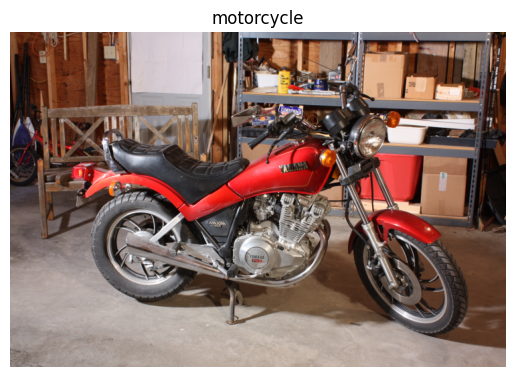

Q: Describe this image.
LLaVA: The image features a red motorcycle parked in a garage. The motorcycle is prominently displayed in the scene, occupying a significant portion of the image. 

In the background, there are several items scattered around the garage. A chair is located near the left side of the motorcycle, while a dining table can be seen in the middle of the scene. Additionally, there are two bowls placed on the table, and a bottle is located on the right side of the scene.
Actual: A red motorcycle parked in a garage, shelves with cardboard boxes behind it, no people.

Q: What color is the motorcycle?
LLaVA: The motorcycle is red.
Actual: Red (black seat)

Q: What is behind the motorcycle?
LLaVA: Behind the motorcycle, there is a storage area or a garage.
Actual: Metal shelves with boxes and storage bins

Q: Is anyone sitting on the motorcycle?
LLaVA: No, the motorcycle is parked and has no one sitting on it.
Actual: No



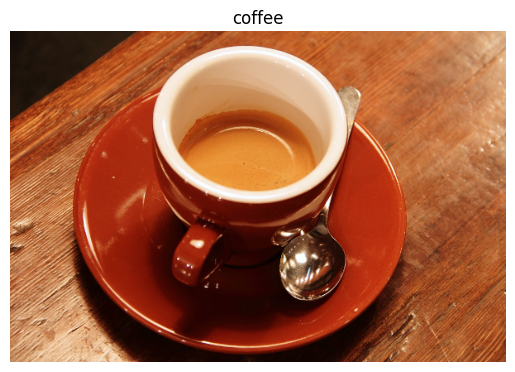

Q: Describe this image.
LLaVA: The image features a small cup of coffee placed on a dining table. The cup is filled with a dark liquid, likely coffee, and it appears to be a single serving. The cup is positioned towards the center of the table, and a spoon is resting on the table next to it. The scene suggests a simple and cozy coffee break.
Actual: A cup of espresso on a red saucer with a metal spoon, on a wooden table.

Q: How many spoons are there?
LLaVA: There are two spoons in the image.
Actual: One

Q: Where is the spoon?
LLaVA: The spoon is on the saucer, which is placed on the dining table.
Actual: On the saucer, next to the cup

Q: What is written on the cup?
LLaVA: The cup has the word "Coffee" written on it.
Actual: Nothing, there is no text



In [ ]:
questions = {
    "astronaut": [
        ("Describe this image.", "A smiling woman astronaut in an orange suit holding a helmet, a US flag on the left and a space shuttle model on the right."),
        ("What color is the person's suit?", "Orange"),
        ("What is the person holding?", "A helmet"),
        ("What is written on the name tag?", "Too small to read clearly"),
    ],
    "motorcycle": [
        ("Describe this image.", "A red motorcycle parked in a garage, shelves with cardboard boxes behind it, no people."),
        ("What color is the motorcycle?", "Red (black seat)"),
        ("What is behind the motorcycle?", "Metal shelves with boxes and storage bins"),
        ("Is anyone sitting on the motorcycle?", "No"),
    ],
    "coffee": [
        ("Describe this image.", "A cup of espresso on a red saucer with a metal spoon, on a wooden table."),
        ("How many spoons are there?", "One"),
        ("Where is the spoon?", "On the saucer, next to the cup"),
        ("What is written on the cup?", "Nothing, there is no text"),
    ],
}

vlm_rows = []
for name, qa_list in questions.items():
    plt.imshow(images[name]); plt.axis("off"); plt.title(name); plt.show()
    for question, actual in qa_list:
        answer = ask(images[name], question)
        print(f"Q: {question}\nLLaVA: {answer}\nActual: {actual}\n")
        vlm_rows.append({"image": name, "question": question, "LLaVA answer": answer, "actual": actual})

All recorded answers next to the actual image content:

In [ ]:
pd.set_option("display.max_colwidth", None)
pd.DataFrame(vlm_rows)

,image,question,LLaVA answer,actual
0,astronaut,Describe this image.,"The image features a woman wearing an orange space suit, standing in front of a flag. She appears to be a space explorer, possibly a female astronaut. The woman is smiling, showcasing her enthusiasm for the space program.\n\nIn the background, there are two airplanes visible, one on the left side and the other on the right side of the image. The presence of these airplanes suggests that the location might be near an airport or an airbase.","A smiling woman astronaut in an orange suit holding a helmet, a US flag on the left and a space shuttle model on the right."
1,astronaut,What color is the person's suit?,The person's suit is orange.,Orange
2,astronaut,What is the person holding?,The person is holding a space suit.,A helmet
3,astronaut,What is written on the name tag?,"The name tag on the woman's shirt reads ""Sally.""",Too small to read clearly (it says Eileen Collins)
4,motorcycle,Describe this image.,"The image features a red motorcycle parked in a garage. The motorcycle is prominently displayed in the scene, occupying a significant portion of the image. \n\nIn the background, there are several items scattered around the garage. A chair is located near the left side of the motorcycle, while a dining table can be seen in the middle of the scene. Additionally, there are two bowls placed on the table, and a bottle is located on the right side of the scene.","A red motorcycle parked in a garage, shelves with cardboard boxes behind it, no people."
5,motorcycle,What color is the motorcycle?,The motorcycle is red.,Red (black seat)
6,motorcycle,What is behind the motorcycle?,"Behind the motorcycle, there is a storage area or a garage.",Metal shelves with boxes and storage bins
7,motorcycle,Is anyone sitting on the motorcycle?,"No, the motorcycle is parked and has no one sitting on it.",No
8,coffee,Describe this image.,"The image features a small cup of coffee placed on a dining table. The cup is filled with a dark liquid, likely coffee, and it appears to be a single serving. The cup is positioned towards the center of the table, and a spoon is resting on the table next to it. The scene suggests a simple and cozy coffee break.","A cup of espresso on a red saucer with a metal spoon, on a wooden table."
9,coffee,How many spoons are there?,There are two spoons in the image.,One


### Answers — Task 3

**1. How does the output of a generative VLM differ from CLIP's output?**
CLIP only outputs similarity scores for the labels we give it — it can choose between options but cannot write anything. LLaVA generates free text: it wrote full descriptions of the images and answered our questions in natural language. CLIP's output is a number for each label, LLaVA's output is sentences, which are richer but have no score and are harder to check automatically.

**2. Can the VLM answer questions that were not predefined as candidate labels? Explain.**
Yes. We never gave LLaVA a list of possible answers, but it answered questions about colour ("The person's suit is orange"), location ("The spoon is on the saucer"), counting and yes/no questions. This is possible because LLaVA connects an image encoder to a large language model, which generates the answer word by word from its whole vocabulary. CLIP could only answer if the correct answer was already in our list of labels. However, being able to answer does not mean the answer is correct.

**3. Did the model generate any incorrect or unsupported information?**
Yes, a lot. Of the 9 short questions, only 4 were answered correctly (suit colour, motorcycle colour, nobody sitting on the motorcycle, the spoon on the saucer), and "a storage area or a garage" behind the motorcycle is only partly correct (it does not mention the shelves and boxes). The mistakes:
- **Astronaut:** it said the person is holding *"a space suit"* — she is holding a helmet. It said the name tag reads *"Sally"* — the text is too small to read. The description says there are *"two airplanes"* in the background and that the place is *"near an airport or an airbase"* — there are no airplanes, only a US flag and a space shuttle model.
- **Motorcycle:** the description invents *"a dining table"*, *"two bowls"* on it and *"a bottle"* — none of these are in the image; behind the motorcycle there are shelves with boxes.
- **Coffee:** it said there are *"two spoons"* — there is only one. It said the cup has the word *"Coffee"* written on it — there is no text on the cup. The description says the spoon is *"on the table next to"* the cup, but in another answer the model said (correctly) that it is on the saucer, so the model even contradicted itself.

The simple questions about large, clear things (the main colours) were answered correctly; the mistakes appeared in small details, counting, text and the background of the descriptions.

**4. What is hallucination in VLMs, and did you observe an example?**
Hallucination is when a VLM generates information that sounds correct and confident but is not actually in the image — objects that are not there, wrong counts, or invented text. It happens because the language model writes what is *likely* in such a scene, even when the image does not show it.
Yes, we observed several examples:
- The name tag *"Sally"*: the text cannot be read, so the model invented a name. Sally Ride is a famous female astronaut, so the model probably used its language knowledge ("woman + astronaut → Sally") instead of the image.
- The word *"Coffee"* written on the cup, although the cup has no text — it is a coffee cup, so the model "expected" this word.
- The *"two airplanes"* in the astronaut image and the *"dining table, two bowls and a bottle"* in the garage — objects that do not exist in the images.

**5. Which model would you choose for image classification, and which for detailed image descriptions? Justify your answers.**
- **Image classification → CLIP.** In Task 1 it classified all 5 images correctly with probabilities above 0.86. It is much smaller and faster than LLaVA, it gives a score for every class, its answer is always one of the given labels, and the list of classes can be changed without retraining.
- **Detailed descriptions → LLaVA.** Only a generative model can describe a whole scene and answer open questions about colours, positions and relationships — CLIP cannot do this at all. However, our results show that LLaVA's answers must be checked, because it made mistakes in about half of the questions and hallucinated objects and text in its descriptions.